# 03 — Model Selection (Validation Set)

Compare model families and hyperparameters under three rules:
1. **Same 80/20 stratified split** for every run (official test set stays untouched), leak-free: identical rows never sit on both sides.
2. **Primary metric: F1** (spec 8.3), alongside **FPR**, training time, and model size.
3. **Log every run** to avoid cherry-picking; re-check the final winner once on test.

## 1. Setup & evaluation harness

In [1]:
import io
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from cybershield.ml.preprocessing import TRAIN_CSV, build_preprocessor, load_csv, split_xy, validation_split
from cybershield.ml.train import SEED, build_model, evaluate

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

X, y = split_xy(load_csv(TRAIN_CSV))
X_fit, X_val, y_fit, y_val = validation_split(X, y)

results = []


def run_experiment(name, pipeline, **settings):
    start = time.perf_counter()
    pipeline.fit(X_fit, y_fit)
    train_s = time.perf_counter() - start

    m = evaluate(y_val, pipeline.predict(X_val))
    buf = io.BytesIO()
    joblib.dump(pipeline, buf)

    row = {
        "model": name,
        **settings,
        "f1": m["f1"],
        "precision": m["precision"],
        "recall": m["recall"],
        "fpr": m["false_positive_rate"],
        "train_s": train_s,
        "size_mb": buf.tell() / 1e6,
    }
    results.append(row)
    return row


def format_results(rows, cols=None, sort_by=None):
    df = pd.DataFrame(rows)
    if sort_by:
        df = df.sort_values(sort_by, ascending=False)
    if cols:
        df = df[cols]
    df = df.reset_index(drop=True)

    fmt = {
        "f1": "{:.2%}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "fpr": "{:.2%}",
        "train_s": "{:.1f}s",
        "size_mb": "{:.1f} MB",
    }
    if "max_depth" in df.columns:
        df["max_depth"] = df["max_depth"].map(lambda v: "None" if pd.isna(v) else str(int(v)))
    if "class_weight" in df.columns:
        df["class_weight"] = df["class_weight"].fillna("None")

    return df.style.format({k: v for k, v in fmt.items() if k in df.columns}, na_rep="—")

## 2. Three model families

| Model | How it works | Needs scaling? |
|---|---|---|
| **Logistic Regression** | Single linear boundary over weighted features; fast and interpretable. | **Yes** — large byte counts would otherwise drown small flags. |
| **Random Forest** | Many deep trees trained independently on random samples; they vote. | No |
| **HistGradientBoosting** | Trees built sequentially, each fixing earlier errors; strong on tabular data. | No |

For Logistic Regression we test plain `StandardScaler` vs. `log1p` + `StandardScaler` (squashes skewed byte/rate columns).

In [2]:
def make_logreg(use_log=False):
    steps = [("preprocess", build_preprocessor())]
    if use_log:
        steps.append(("log", FunctionTransformer(np.log1p)))  # safe: no negative values
    steps += [
        ("scale", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000)),
    ]
    return Pipeline(steps)


baseline_rows = [
    run_experiment("logreg", make_logreg(use_log=False), inputs="scaled"),
    run_experiment("logreg", make_logreg(use_log=True), inputs="log+scaled"),
    run_experiment("random_forest", build_model(), inputs="default (100 trees)"),
    run_experiment("hist_gb", build_model(HistGradientBoostingClassifier(random_state=SEED)), inputs="default"),
]
format_results(baseline_rows)

,model,inputs,f1,precision,recall,fpr,train_s,size_mb
0,logreg,scaled,95.42%,92.26%,98.80%,17.65%,9.9s,0.0 MB
1,logreg,log+scaled,95.62%,93.81%,97.50%,13.71%,11.1s,0.0 MB
2,random_forest,default (100 trees),96.71%,95.76%,97.67%,9.21%,2.6s,85.8 MB
3,hist_gb,default,96.69%,95.74%,97.65%,9.25%,2.4s,0.4 MB


## 3. Random Forest: number of trees
More trees usually improve F1 up to an elbow, while training time and model size grow linearly.

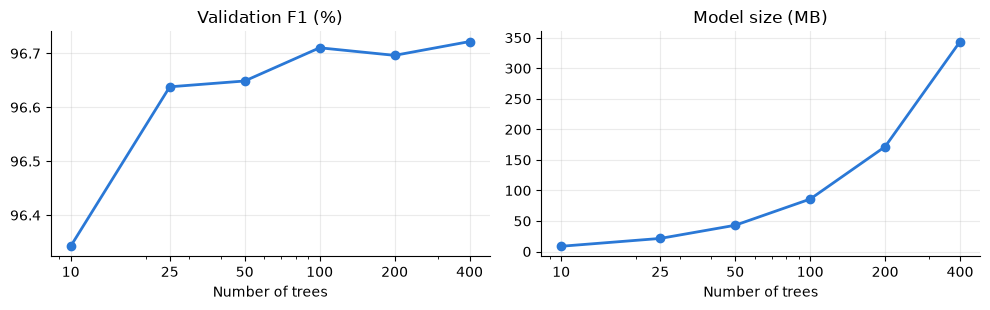

,n_estimators,f1,fpr,train_s,size_mb
0,10,96.34%,8.30%,0.6s,8.6 MB
1,25,96.64%,9.24%,0.8s,21.4 MB
2,50,96.65%,9.11%,1.2s,43.0 MB
3,100,96.71%,9.21%,1.9s,85.8 MB
4,200,96.70%,9.27%,3.9s,171.7 MB
5,400,96.72%,9.26%,7.5s,343.8 MB


In [3]:
tree_counts = [10, 25, 50, 100, 200, 400]
curve_rows = [
    run_experiment(
        "random_forest",
        build_model(RandomForestClassifier(n_estimators=n, random_state=SEED, n_jobs=-1)),
        n_estimators=n,
    )
    for n in tree_counts
]
curve_df = pd.DataFrame(curve_rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, scale, title in [
    (axes[0], "f1", 100, "Validation F1 (%)"),
    (axes[1], "size_mb", 1, "Model size (MB)"),
]:
    ax.plot(curve_df["n_estimators"], curve_df[col] * scale, marker="o", color="#2a78d6", linewidth=2)
    ax.set(xscale="log", xticks=tree_counts, xticklabels=tree_counts, xlabel="Number of trees", title=title)

plt.tight_layout()
plt.show()

format_results(curve_rows, cols=["n_estimators", "f1", "fpr", "train_s", "size_mb"])

## 4. Random Forest: hyperparameter grid
- `max_depth`: max tree depth (`None` = grow until pure); shallower trees reduce overfitting.
- `min_samples_leaf`: minimum training rows per leaf; higher values smooth out one-off rules.
- `class_weight="balanced"`: up-weights normal flows (32% of train) to push down false alarms.

Grid size: 3 × 3 × 2 = 18 runs at 50 trees each (past the elbow above).

In [4]:
rf_param_grid = ParameterGrid({
    "max_depth": [None, 20, 10],
    "min_samples_leaf": [1, 5, 20],
    "class_weight": [None, "balanced"],
})

rf_rows = [
    run_experiment(
        "random_forest",
        build_model(RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=-1, **params)),
        **params,
    )
    for params in rf_param_grid
]

format_results(
    rf_rows,
    cols=["max_depth", "min_samples_leaf", "class_weight", "f1", "precision", "recall", "fpr", "size_mb"],
    sort_by="f1",
)

,max_depth,min_samples_leaf,class_weight,f1,precision,recall,fpr,size_mb
0,None,5,None,96.68%,95.34%,98.06%,10.21%,15.4 MB
1,20,1,None,96.68%,95.51%,97.89%,9.81%,19.9 MB
2,20,5,None,96.66%,95.10%,98.27%,10.79%,10.5 MB
3,None,1,None,96.65%,95.80%,97.51%,9.11%,43.0 MB
4,None,1,balanced,96.55%,97.13%,95.99%,6.04%,45.2 MB
5,None,20,None,96.46%,94.66%,98.34%,11.83%,5.0 MB
6,None,5,balanced,96.42%,97.35%,95.51%,5.54%,16.7 MB
7,20,20,None,96.42%,94.59%,98.32%,11.97%,4.7 MB
8,20,1,balanced,96.38%,97.56%,95.23%,5.08%,21.9 MB
9,20,5,balanced,96.19%,97.59%,94.83%,4.99%,11.5 MB


## 5. HistGradientBoosting: hyperparameter grid
- `learning_rate`: step size per boosting round (smaller = more conservative).
- `max_leaf_nodes`: complexity cap per tree.
- `max_iter=300`: max rounds (early stopping halts when internal validation stops improving).

In [5]:
hgb_param_grid = ParameterGrid({
    "learning_rate": [0.05, 0.1, 0.2],
    "max_leaf_nodes": [15, 31, 63],
})

hgb_rows = [
    run_experiment(
        "hist_gb",
        build_model(HistGradientBoostingClassifier(random_state=SEED, max_iter=300, **params)),
        **params,
    )
    for params in hgb_param_grid
]

format_results(
    hgb_rows,
    cols=["learning_rate", "max_leaf_nodes", "f1", "precision", "recall", "fpr", "train_s", "size_mb"],
    sort_by="f1",
)

,learning_rate,max_leaf_nodes,f1,precision,recall,fpr,train_s,size_mb
0,0.100000,63,96.88%,96.22%,97.54%,8.16%,4.8s,1.9 MB
1,0.050000,63,96.87%,96.03%,97.72%,8.60%,5.8s,2.2 MB
2,0.100000,31,96.82%,96.05%,97.61%,8.55%,4.8s,1.1 MB
3,0.200000,63,96.82%,96.25%,97.40%,8.08%,3.0s,1.1 MB
4,0.050000,31,96.79%,96.01%,97.58%,8.64%,4.9s,1.1 MB
5,0.100000,15,96.75%,96.09%,97.41%,8.46%,3.8s,0.6 MB
6,0.200000,31,96.70%,96.11%,97.31%,8.40%,3.0s,0.7 MB
7,0.050000,15,96.65%,95.72%,97.59%,9.30%,4.5s,0.6 MB
8,0.200000,15,96.53%,95.67%,97.41%,9.40%,1.4s,0.2 MB


## 6. Best of each family

In [6]:
all_runs = pd.DataFrame(results)
best_idx = all_runs.groupby("model")["f1"].idxmax()
best = all_runs.loc[best_idx].dropna(axis=1, how="all")

print(f"Total runs logged: {len(all_runs)}")
format_results(best.to_dict("records"), sort_by="f1")

Total runs logged: 37


,model,inputs,f1,precision,recall,fpr,train_s,size_mb,n_estimators,learning_rate,max_leaf_nodes
0,hist_gb,—,96.88%,96.22%,97.54%,8.16%,4.8s,1.9 MB,—,0.100000,63.000000
1,random_forest,—,96.72%,95.74%,97.72%,9.26%,7.5s,343.8 MB,400.000000,—,—
2,logreg,log+scaled,95.62%,93.81%,97.50%,13.71%,11.1s,0.0 MB,—,—,—


## Key takeaways
- **HistGradientBoosting** wins on validation F1 while being ~45× smaller (~1.9 MB vs. ~86 MB at 100 trees) and faster to train than Random Forest.
- **Random Forest** plateaus around 50–100 trees; `class_weight="balanced"` trades a small drop in F1 for lower FPR.
- **Logistic Regression** benefits clearly from `log1p` scaling on skewed features, though tree ensembles still lead.